In [ ]:
import torch
import torchvision
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader, random_split

print(torch.__version__)

2.11.0+cpu


In [ ]:
transform = transforms.ToTensor()

dataset = datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 301kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.53MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.6MB/s]


In [ ]:
print("Nombre total d'images :", len(dataset))

Nombre total d'images : 60000


In [ ]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size]
)

In [ ]:
print(len(train_dataset))
print(len(val_dataset))

48000
12000


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

In [ ]:
import torch.nn as nn

In [ ]:
class FashionClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(

            nn.Flatten(),

            nn.Linear(28 * 28, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.model(x)

In [ ]:
model = FashionClassifier()

print(model)

FashionClassifier(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [ ]:
criterion = nn.CrossEntropyLoss()

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
num_epochs = 5

for epoch in range(num_epochs):

    running_loss = 0.0

    for images, labels in train_loader:

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")

Epoch [1/5], Loss: 0.5912
Epoch [2/5], Loss: 0.4098
Epoch [3/5], Loss: 0.3682
Epoch [4/5], Loss: 0.3404
Epoch [5/5], Loss: 0.3210


In [ ]:
model.eval()

FashionClassifier(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [ ]:
correct = 0
total = 0

with torch.no_grad():

    for images, labels in val_loader:

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Accuracy sur les données de validation : {accuracy:.2f}%")

Accuracy sur les données de validation : 86.66%


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

In [ ]:
images, labels = next(iter(val_loader))

In [ ]:
model.eval()

with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

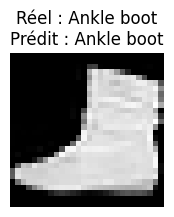

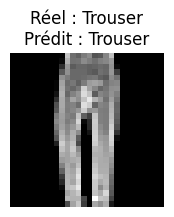

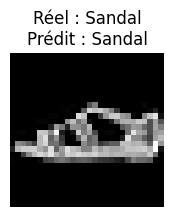

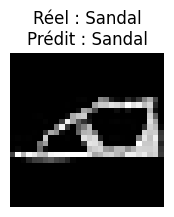

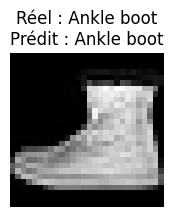

In [ ]:
for i in range(5):

    plt.figure(figsize=(2,2))

    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(
        f"Réel : {classes[labels[i]]}\n"
        f"Prédit : {classes[predicted[i]]}"
    )

    plt.axis("off")
    plt.show()